# CHAZ on a climate model

This notebook runs one CMIP6 model through CHAZ: UKESM1-0-LL, member r1i1p1f2, the member that
Fosu et al. (2024) downscaled. The aim is to see the pipeline work on a climate model and to find
problems before the winds and rasters. UKESM is the warmest of the six models in Meiler's hazard
maps, so SSP5-8.5 in 2081–2100 takes the inputs furthest from the climate that the CHAZ
regressions were fit on.

- Forcing (`ocr.risks.hurricane.cmip`): historical 1981–2014 and SSP5-8.5 2081–2100 from the
  public CMIP6 store on AWS, regridded to CHAZ's 2° grid.
- Genesis: the TCGI fields bias-corrected toward ERA5 (§1); the seeding ratio from the corrected
  historical index of 1981–2005, kept for 2081–2100.
- Tracks and intensity: the model's own winds, humidity and potential intensity, uncorrected, as
  in Fosu et al. (2024) §2.2, with the intensity predictors normalized for the model (§2).
- CHAZ (`ocr.risks.hurricane.chaz`): 1995–2014 and 2081–2100, TCGI-CRH and TCGI-SD, 10 track
  realizations a year with 40 intensity members each, as for our ERA5 run.

Landfall statistics follow the tracks notebook (`ocr.risks.hurricane.landfall`): US landfalls
are those on the Atlantic and Gulf coasts, and landfalls on the US Pacific coast are counted
apart. CHAZ numbers here are per intensity member and not scaled to the observed storm count.

## Decisions

| | choice | evidence |
| --- | --- | --- |
| model and member | UKESM1-0-LL r1i1p1f2, Fosu et al. (2024)'s | |
| genesis correction | ERA5 minus the model's monthly climatology of 1981–2010, added to vorticity, shear, potential intensity, CRH and SD on the 2° grid; this member's climatology, not an ensemble mean; vorticity, shear, potential intensity and CRH clipped at 0 | §1 |
| seeding ratio | from the corrected historical index, 1981–2005, kept for 2081–2100 | |
| track and intensity forcing | the model's fields, uncorrected | Fosu et al. (2024) §2.2 |
| intensity normalization | the tutorial's, mapped from ERA5 to the model by our port of CHAZvBeta's `getMeanStd.py` on the same samples | §2, §5 |
| members above 300 kt | dropped, as CHAZ does | §5 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from ocr.risks.hurricane import chaz, cmip, landfall, meanstd, runaways, store

MODEL, MEMBER = cmip.MODEL, cmip.MEMBER
U = f'cmip6/{MODEL}/{MEMBER}'
BASE, END = (1995, 2014), (2081, 2100)
OBS, ERA5C, CRH, SD, ALT = '#52514e', '#2a78d6', '#eb6834', '#1baf7a', '#8a5cc7'
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
pd.set_option('display.max_columns', 30)

## 1. Genesis index

TCGI for ERA5 and for UKESM before and after the correction, summed over each year and over
each of CHAZ's basins (SH: the three southern ones together), averaged over 1981–2010, the years
the correction is built from.

In [2]:
lon2d, lat2d = np.meshgrid(np.arange(0, 360, 2.0), np.arange(-89, 90, 2.0))
basin = chaz.defineBasin(lon2d, lat2d, *chaz.getbasinMap())
GROUPS = {
    'global': basin > 0,
    'NA': basin == 1,
    'EP': basin == 2,
    'WP': basin == 3,
    'NI': basin == 4,
    'SH': basin >= 5,
}


def by_basin(field):
    t = field.sum('time').values
    return {g: np.nansum(t[m]) for g, m in GROUPS.items()}


rows = []
for kind in ('CRH', 'SD'):
    name = f'TCGI_{kind}_PI'
    for y in range(1981, 2015):
        with xr.open_dataset(store.path(f'forcing/era5/{y}/{name}_{y}.nc')) as ds:
            rows.append({'set': 'ERA5', 'kind': kind, 'year': y, **by_basin(ds['TCGI'])})
    for exp, (y0, y1) in (('historical', cmip.HISTORICAL), ('ssp585', cmip.FUTURE['ssp585'])):
        for y in range(y0, y1 + 1):
            with xr.open_dataset(store.path(f'{cmip.root(exp)}/{y}/{name}_{y}.nc')) as ds:
                rows.append({'set': 'UKESM', 'kind': kind, 'year': y, **by_basin(ds['TCGI'])})
                rows.append(
                    {
                        'set': 'UKESM uncorrected',
                        'kind': kind,
                        'year': y,
                        **by_basin(ds['TCGI_uncorrected']),
                    }
                )
gi = pd.DataFrame(rows)
clim = gi[gi['year'].between(*cmip.CLIMATOLOGY)].groupby(['kind', 'set'])[list(GROUPS)].mean()
clim.round(1).style.format('{:.1f}').set_caption(
    'Genesis index summed over each year, mean 1981–2010 (seeds per year at ratio 1)'
)

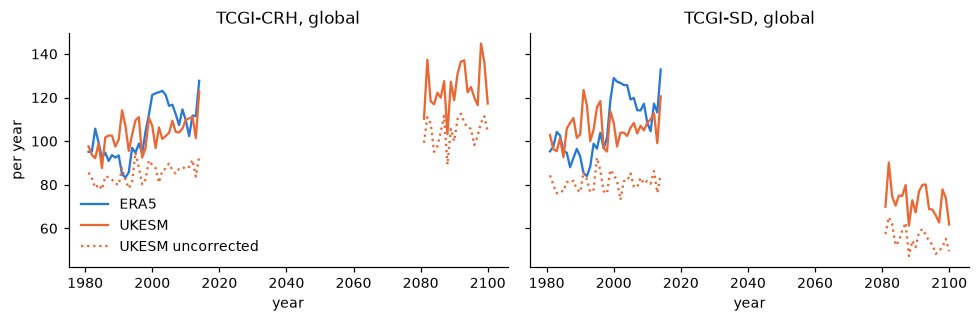

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, kind in zip(axes, ('CRH', 'SD')):
    for s, color, ls in (
        ('ERA5', ERA5C, '-'),
        ('UKESM', CRH, '-'),
        ('UKESM uncorrected', CRH, ':'),
    ):
        d = gi[(gi['kind'] == kind) & (gi['set'] == s)].set_index('year')['global']
        for span in ((1981, 2014), END):
            part = d[(d.index >= span[0]) & (d.index <= span[1])]
            ax.plot(part.index, part, color=color, ls=ls, label=s if span[0] == 1981 else None)
    ax.set(title=f'TCGI-{kind}, global', xlabel='year')
axes[0].set(ylabel='per year')
axes[0].legend(frameon=False)
fig.tight_layout()

Uncorrected, UKESM's index is a fifth to a quarter too low (84.6 against 103.2 a year for CRH,
80.9 against 105.4 for SD) and about a third too low in the North Atlantic. Corrected, it comes
within 1% of ERA5 globally for both versions and within 5% in every basin. The correction removes
each field's mean bias. The index depends on the fields nonlinearly, so its own bias need not
vanish with theirs, though here it nearly does.

In [4]:
def mean(s, k, span):
    sel = (gi['set'] == s) & (gi['kind'] == k) & gi['year'].between(*span)
    return gi.loc[sel, list(GROUPS)].mean()


change = pd.DataFrame({k: mean('UKESM', k, END) / mean('UKESM', k, BASE) for k in ('CRH', 'SD')}).T
change.style.format('{:.2f}').set_caption(
    'UKESM genesis index, 2081–2100 ÷ 1995–2014 (bias-corrected)'
)

,global,NA,EP,WP,NI,SH
CRH,1.18,1.14,1.47,1.17,1.35,1.06
SD,0.68,0.68,0.89,0.68,0.65,0.61


By 2081–2100 the two versions disagree on the sign of the change, as in Camargo et al. (2025):
TCGI-CRH rises 18% globally and 14% in the North Atlantic, and TCGI-SD falls 32% in both. The two indices use different
moisture variables and are fitted separately, so their other coefficients differ too.

In [5]:
corr = xr.open_dataset(store.path(f'forcing/cmip6/{MODEL}/{MEMBER}/genesis_correction.nc')).load()
ocean = corr['ocean']
FIELDS = {  # cmip.correct clips the first four at 0 and leaves the last two as they are
    'avor < 0': lambda c: c['avor'] < 0,
    'vws < 0': lambda c: c['vws'] < 0,
    'PI < 0': lambda c: c['PI'] < 0,
    'CRH < 0': lambda c: c['CRH'] < 0,
    'CRH > 100': lambda c: c['CRH'] > 100,
    'SD > 0': lambda c: c['SD'] > 0,
}
clip = []
for exp, (y0, y1) in (('historical', BASE), ('ssp585', END)):
    for y in range(y0, y1 + 1):
        raw = xr.open_dataset(store.path(f'{cmip.root(exp)}/{y}/genesis_raw_{y}.nc')).load()
        x = raw[cmip.GENESIS].copy()
        x['avor'] = np.abs(x['avor'])
        c = x + corr[cmip.GENESIS].sel(month=raw['time.month']).drop_vars('month')
        with xr.open_dataset(store.path(f'{cmip.root(exp)}/{y}/TCGI_CRH_PI_{y}.nc')) as ds:
            t = ds['TCGI'].load()
        total = float(t.sum())
        row = {'period': f'{y0}–{y1}', 'year': y}
        for v, bad in FIELDS.items():
            b = bad(c) & ocean
            row[f'{v}: cells'] = int(b.sum())
            row[f'{v}: share of TCGI-CRH'] = float(t.where(b).sum()) / total
        clip.append(row)
clip = pd.DataFrame(clip).groupby('period').mean().drop(columns='year')
clip.T.style.format('{:.3g}').set_caption(
    'Ocean cell-months a year where a corrected field leaves its physical range, and the share of '
    'the corrected TCGI-CRH in them'
)

period,1995–2014,2081–2100
avor < 0: cells,199,290
avor < 0: share of TCGI-CRH,2.52e-06,5.95e-06
vws < 0: cells,479,1.1e+03
vws < 0: share of TCGI-CRH,0.036,0.0562
PI < 0: cells,3.01e+03,2.36e+03
PI < 0: share of TCGI-CRH,0.000757,0.000456
CRH < 0: cells,0,0
CRH < 0: share of TCGI-CRH,0,0
CRH > 100: cells,0.4,0
CRH > 100: share of TCGI-CRH,5.4e-07,0


A corrected field leaves its physical range where the model's value plus the correction (ERA5's
mean minus the model's) falls below zero; vorticity, shear, potential intensity and CRH are
clipped at 0 there. Only the shear clip touches cells that carry a noticeable share of the index: 3.6%
of TCGI-CRH in 1995–2014 and 5.6% in 2081–2100. The vorticity and potential intensity clips touch
under 0.1%. CRH rises above 100 in 0.4 cell-months a year in 1995–2014 and never in 2081–2100,
and SD never rises above 0, so neither needs an upper clip in these runs.

## 2. Intensity normalization

The intensity model standardizes each predictor by a mean and standard deviation
(`coefficient_meanstd.nc`) before applying the regression coefficients. CHAZ keeps the
coefficients for every model; for a model, the CHAZ authors recompute the normalization from the
model's fields along the observed tracks of 1981–2012 (CHAZvBeta's `getMeanStd.py`).
`ocr.risks.hurricane.meanstd` ports that script. Run on ERA5, the port does not reproduce the
tutorial's file, even for the predictors that come from the tracks alone (storm wind, its 12-hour
change and its square, and translation speed). The tutorial's file was therefore built from other
track samples than the ones the port selects from the tutorial's track file, or with other
preprocessing. The water regression's predictors:

In [6]:
files = {
    'tutorial': chaz.static('coefficient_meanstd.nc'),
    'ERA5 port': store.path(meanstd.ERA5_PORT),
    'UKESM port': store.path(f'validation/meanstd/{MODEL}_{MEMBER}_port_model.nc'),
    'UKESM mapped': store.path(cmip.meanstd_key()),
}
norm = {k: xr.open_dataset(p).load() for k, p in files.items()}
t = {}
for k, ds in norm.items():
    t[(k, 'mean')] = ds['meanX_w'].values[1:]
    t[(k, 'sd')] = ds['stdX_w'].values[1:]
t = pd.DataFrame(t, index=meanstd.WATER)
t.loc['12-hour change (predictand)'] = [
    float(norm[k][f'{s}Y_w']) for k in norm for s in ('mean', 'std')
]
t.style.format('{:.4g}').set_caption('Water regression: mean and sd of each predictor')

The port's environment differs from the tutorial's too: potential intensity minus wind averages
76 kt against 30 kt, with a smaller spread (44 against 70 kt). We use neither port directly. The
model's normalization ('UKESM mapped') is the tutorial's, shifted and scaled by how the model's
port differs from the ERA5 port on the same samples. Under UKESM, each standardized predictor then
has the mean and standard deviation that the tutorial's normalization gives it under ERA5; its
tails and its correlation with other predictors can still differ. The entries that come from the
tracks alone, and the predictand, keep the tutorial's values. UKESM's lower potential intensity along the tracks
lowers the mean of potential intensity minus wind to 26 kt, and narrows the spread of its square
by 12% and of its cube by 17%; §5 shows what that does.

## 3. Present day (1995–2014)

Storm counts, intensity and US landfall from UKESM's historical runs against our ERA5 run
(TCGI-CRH) and IBTrACS, 1995–2014.

In [7]:
RUNS = {
    'ERA5': ('era5', 'TCGI_CRH_PI', BASE),
    'UKESM CRH': (f'{U}/historical', 'TCGI_CRH_PI', BASE),
    'UKESM SD': (f'{U}/historical', 'TCGI_SD_PI', BASE),
    'UKESM CRH 2081–2100': (f'{U}/ssp585', 'TCGI_CRH_PI', END),
    'UKESM SD 2081–2100': (f'{U}/ssp585', 'TCGI_SD_PI', END),
    'UKESM CRH, tutorial normalization': (
        f'{U}/historical',
        'TCGI_CRH_PI-normalization-tutorial',
        BASE,
    ),
    'UKESM CRH 2081–2100, tutorial normalization': (
        f'{U}/ssp585',
        'TCGI_CRH_PI-normalization-tutorial',
        END,
    ),
}
rows, files_ = {}, {}
for name, (source, run, years) in RUNS.items():
    key = landfall.rows_key(source, run, years)
    rows[name] = pd.read_parquet(store.path(f'{key}.parquet'))
    files_[name] = pd.read_csv(store.path(f'{key}_files.csv'))
obs = pd.read_parquet(store.path(f'{landfall.OUT}/rows_ibtracs.parquet'))
obs = obs[obs['year'].between(*BASE)]

KEEP = [
    'NA TS storms/yr',
    'NA share peak >= 64 kt',
    'NA share peak >= 96 kt',
    'US landfalls/yr (>= 34 kt)',
    'US landfalls/yr >= 64 kt',
    'US landfalls/yr >= 96 kt',
    'landfall share of NA TS storms',
    'landfall wind median (kt)',
    'TX-AL landfalls/yr >= 64 kt',
    'FL landfalls/yr >= 64 kt',
    'GA-Car landfalls/yr >= 64 kt',
    'VA-ME landfalls/yr >= 64 kt',
    'US Pacific landfalls/yr (>= 34 kt)',
]


def summary(name):
    r, f = rows[name], files_[name]
    years = f['year'].nunique()
    members = f['realization'].nunique() * chaz.MEMBERS
    s = landfall.summarize(r, members * years, 1.0)
    out = {k: s[k] for k in KEEP}
    per_file = f.groupby('year')[['storms', 'ts_storms_per_member']].mean()
    out['global storms kept/yr'] = per_file['storms'].mean()
    out['global TS storms/yr, per member'] = per_file['ts_storms_per_member'].mean()
    return out


s = {'IBTrACS': {k: landfall.summarize(obs, BASE[1] - BASE[0] + 1, 1.0)[k] for k in KEEP}}
s.update({n: summary(n) for n in RUNS})
s = pd.DataFrame(s)
s[['IBTrACS', 'ERA5', 'UKESM CRH', 'UKESM SD']].style.format('{:.3f}').set_caption(
    'Per year, 1995–2014 (CHAZ: per intensity member, unscaled)'
)

,IBTrACS,ERA5,UKESM CRH,UKESM SD
NA TS storms/yr,15.550,13.966,14.483,14.969
NA share peak >= 64 kt,0.514,0.461,0.471,0.456
NA share peak >= 96 kt,0.228,0.199,0.207,0.196
US landfalls/yr (>= 34 kt),3.350,2.802,2.769,2.957
US landfalls/yr >= 64 kt,1.500,0.825,0.763,0.792
US landfalls/yr >= 96 kt,0.150,0.169,0.141,0.154
landfall share of NA TS storms,0.215,0.201,0.191,0.198
landfall wind median (kt),55.000,51.606,50.541,50.352
TX-AL landfalls/yr >= 64 kt,0.600,0.392,0.360,0.373
FL landfalls/yr >= 64 kt,0.500,0.280,0.285,0.274


UKESM reproduces our ERA5 run closely. Per year it makes 14.5 (CRH) and 15.0 (SD) North Atlantic
tropical storms against 14.0 for ERA5 and 15.6 observed, 2.77 and 2.96 US landfalls against 2.80
(3.35 observed), and 0.76 and 0.79 US hurricane landfalls against 0.83. All three fall short of the
observed 1.50 hurricane landfalls, as CHAZ on ERA5 does (tracks notebook), and come near the
observed 0.15 major landfalls (0.14–0.17). They also make 0.35–0.42 landfalls a year on the US
Pacific coast, where none were observed. Only the genesis fields are bias-corrected, but the model
normalization (§2) moves the means and spreads of the intensity predictors to ERA5's, and errors in
steering and intensity could offset each other. This agreement therefore does not show that
UKESM's raw environment is unbiased.

## 4. 2081–2100 against 1995–2014

The same statistics for SSP5-8.5 in 2081–2100, as a ratio to 1995–2014 (§3).

In [8]:
fut = pd.DataFrame(
    {
        'CRH': s['UKESM CRH 2081–2100'] / s['UKESM CRH'],
        'SD': s['UKESM SD 2081–2100'] / s['UKESM SD'],
    }
)
fut.style.format('{:.2f}').set_caption('UKESM ssp585, 2081–2100 ÷ 1995–2014')

,CRH,SD
NA TS storms/yr,0.94,0.57
NA share peak >= 64 kt,0.94,0.94
NA share peak >= 96 kt,0.98,0.97
US landfalls/yr (>= 34 kt),0.70,0.36
US landfalls/yr >= 64 kt,0.63,0.31
US landfalls/yr >= 96 kt,0.63,0.29
landfall share of NA TS storms,0.74,0.64
landfall wind median (kt),0.96,0.95
TX-AL landfalls/yr >= 64 kt,0.53,0.24
FL landfalls/yr >= 64 kt,0.55,0.29


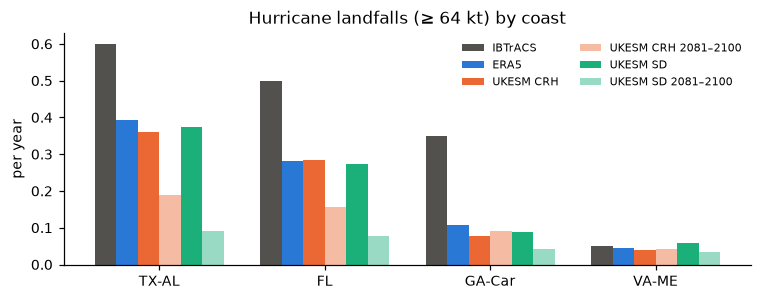

In [9]:
regions = ['TX-AL', 'FL', 'GA-Car', 'VA-ME']
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(len(regions))
bars = [
    ('IBTrACS', OBS),
    ('ERA5', ERA5C),
    ('UKESM CRH', CRH),
    ('UKESM CRH 2081–2100', CRH),
    ('UKESM SD', SD),
    ('UKESM SD 2081–2100', SD),
]
for k, (name, color) in enumerate(bars):
    ax.bar(
        x + (k - 2.5) * 0.13,
        [s.loc[f'{r} landfalls/yr >= 64 kt', name] for r in regions],
        0.13,
        color=color,
        alpha=0.45 if '2081' in name else 1,
        label=name,
    )
ax.set_xticks(x, regions)
ax.set(ylabel='per year', title='Hurricane landfalls (≥ 64 kt) by coast')
ax.legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout()

The genesis version sets the size of the change. With TCGI-CRH, North Atlantic storms fall 6%, US
landfalls 30% and hurricane and major landfalls 37%; with TCGI-SD, storms fall 43%, US landfalls
64% and hurricane landfalls 69%. In both, a smaller share of North Atlantic storms reaches the US
(0.74 and 0.64 of the 1995–2014 share). The shares of North Atlantic storms peaking at 64 and
96 kt change by 6% or less, and the median landfall wind falls 4–5%.

The loss is on the Gulf and Florida coasts, where hurricane landfalls about halve with CRH (0.53,
0.55) and fall to a quarter to a third with SD (0.24, 0.29). From Georgia to Maine, where CHAZ
makes few hurricane landfalls, they rise 10–17% with CRH and fall 40–51% with SD. Landfalls on the
US Pacific coast double with CRH (2.18 times). Globally the CRH run keeps 17% more storms, but 3%
fewer reach tropical-storm strength. The SD run keeps 32% fewer, and 43% fewer reach
tropical-storm strength.

## 5. Members dropped above 300 kt

CHAZ drops an intensity member whose wind passes 300 kt anywhere along its track. With our mapped
normalization UKESM loses 0.9–1.0% of the member slots of the storms it keeps, present day
included; with the tutorial's, 0.5%. Our ERA5 run loses 0.35%. The run files count dropped members of every seeded storm, the test
only those of storms CHAZ keeps (outside 2° of the equator and inside a basin).

In [10]:
def dropped(f):
    """Dropped members over the member slots of the storms a run keeps, which include the
    dropped members' slots."""
    if f['dropped_over_300kt'].isna().any():
        return np.nan  # not recorded in this run's files
    return f['dropped_over_300kt'].sum() / f['members'].sum()


pd.Series(
    {n: dropped(f) for n, f in files_.items()}, name='share of members'
).to_frame().style.format('{:.4f}').set_caption('Members CHAZ dropped above 300 kt, whole runs')

,share of members
ERA5,0.0035
UKESM CRH,0.0102
UKESM SD,0.0096
UKESM CRH 2081–2100,0.0088
UKESM SD 2081–2100,0.0087
"UKESM CRH, tutorial normalization",0.0053
"UKESM CRH 2081–2100, tutorial normalization",0.0053


The water regression shows how a member gets there. Its predictors include the gap between the
ring potential intensity and the wind, and the gap's square and cube. Take a storm whose wind did
not change over the previous 12 hours, with translation speed, shear and humidity at their means.
If the storm is well above its potential intensity, the regression weakens it while the gap is
under 95–131 kt and strengthens it when the gap is wider, faster the wider the gap. A strong storm carried quickly over cold
water can cross that line, and from there each step widens the gap. UKESM's mapped normalization
lowers the line by 9–10 kt. Along a real track the potential intensity, the previous change and
the random error change every step, so the line marks where runaways become likely rather than a
fixed threshold.

,PI 20 kt,PI 60 kt,PI 120 kt
UKESM mapped,95,107,121
tutorial,104,117,131


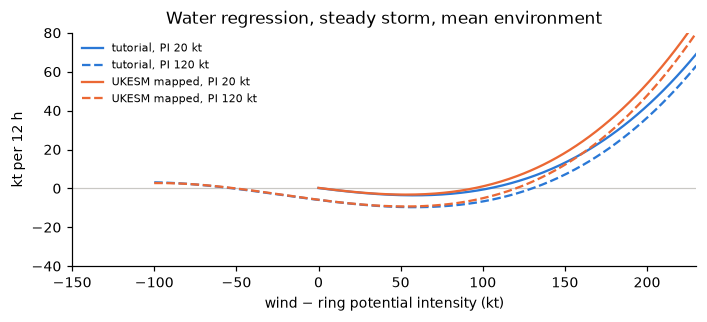

In [11]:
with xr.open_dataset(chaz.static('result_w.nc')) as f:
    coef = f['params'].values


def dv(v, pi, ds):
    """Water regression's 12-hour change at wind v and ring PI pi, for a storm whose wind did
    not change over the previous 12 hours, with translation speed, shear and humidity at their
    means."""
    mX, sX = ds['meanX_w'].values, ds['stdX_w'].values
    x = {
        'StormMwspd': v,
        'dVdt': 0.0,
        'trSpeed': mX[3],
        'dPIwspd': pi - v,
        'SHRD': mX[5],
        'rhMean': mX[6],
        'dPIwspd2': (pi - v) ** 2,
        'dPIwspd3': (pi - v) ** 3,
        'dVdt2': 0.0,
    }
    dy = coef[0] + sum((x[p] - mX[k]) / sX[k] * coef[k] for k, p in enumerate(meanstd.WATER, 1))
    return dy * float(ds['stdY_w']) + float(ds['meanY_w'])


v = np.arange(20, 351, 1.0)
fig, ax = plt.subplots(figsize=(6.5, 3))
for (k, color), pi in [
    ((k, c), p) for k, c in (('tutorial', ERA5C), ('UKESM mapped', CRH)) for p in (20, 120)
]:
    ax.plot(
        v - pi,
        [dv(w, pi, norm[k]) for w in v],
        color=color,
        ls='-' if pi == 20 else '--',
        label=f'{k}, PI {pi} kt',
    )
ax.axhline(0, color='#c9c8c4', lw=0.8, zorder=0)
ax.set(
    xlabel='wind − ring potential intensity (kt)',
    ylabel='kt per 12 h',
    ylim=(-40, 80),
    xlim=(-150, 230),
    title='Water regression, steady storm, mean environment',
)
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()

tip = {}
for k in ('tutorial', 'UKESM mapped'):
    for pi in (20, 60, 120):
        d = np.array([dv(w, pi, norm[k]) for w in v])
        up = next(w for i, w in enumerate(v) if w > pi and (d[i:] > 0).all())
        tip[(k, f'PI {pi} kt')] = up - pi
pd.Series(tip).unstack()[['PI 20 kt', 'PI 60 kt', 'PI 120 kt']].style.format('{:.0f}').set_caption(
    'Wind above ring PI beyond which the regression only strengthens (kt)'
)

The test reruns intensity on the same tracks (two years and four realizations for each forcing)
under each normalization. On UKESM's tracks in 1995–2014 the mapped normalization drops 0.96% of
members and the tutorial's 0.52%, and the mapped one drops more in all 8 realization-years; on
ERA5's tracks the tutorial's drops 0.30%. UKESM drops 0.66 points more than ERA5; switching the
normalization on UKESM's own tracks accounts for 0.44 points of that, about two thirds. The
remaining 0.22 points compare different tracks, seeds and fields, so they are not a clean measure
of UKESM's environment. In 2081–2100 the mapped normalization drops 0.92% and the tutorial's
0.61%; these are two years per period, so they do not show how the rate changes over the century.

Under the mapped and tutorial normalizations, dropped members start running away at median
latitudes of 37–40°, with median winds of 81–91 kt where the ring potential intensity is 18–22 kt,
and pass 300 kt 90–96 hours later. Most come from western North Pacific storms (58–66%), 6–10% from
North Atlantic ones. The raw ports drop fewer (0.11% on ERA5, 0.19% on UKESM), and more of theirs
make their largest jump under the land regression (30–57%). Neither port is used in the runs.

In [12]:
counts = pd.read_csv(store.path(f'{runaways.OUT}/counts.csv'))
drop = pd.read_parquet(store.path(f'{runaways.OUT}/dropped.parquet'))
drop = drop[drop['valid']].assign(hours_to_300=lambda d: 6 * (d['t300'] - d['t_onset']))
counts['members'] = counts['storms'] * runaways.MEMBERS
g = counts.groupby(['source', 'norm'])[['dropped', 'members']].sum()
g['share'] = g['dropped'] / g['members']
wide = counts.pivot_table(index=['source', 'year', 'r'], columns='norm', values='dropped')
g['realization-years above tutorial'] = [
    ''
    if n == 'tutorial'
    else f'{(wide.loc[src, n] > wide.loc[src, "tutorial"]).sum()} of {len(wide.loc[src])}'
    for src, n in g.index
]
g.style.format({'share': '{:.4f}'}).set_caption(
    'Same tracks, intensity under each normalization: two years and four realizations per forcing'
)

In [13]:
on = drop.groupby(['source', 'norm']).agg(
    members=('v_onset', 'size'),
    wind_at_onset=('v_onset', 'median'),
    ring_PI_at_onset=('PI_onset', 'median'),
    gap_at_onset=('gap_onset', 'median'),
    abs_lat_at_onset=('lat_onset', lambda x: x.abs().median()),
    hours_onset_to_300kt=('hours_to_300', 'median'),
    water_regression_at_largest_jump=('regression', lambda x: (x == 'water').mean()),
)
on.style.format('{:.2f}').set_caption(
    'Dropped members at their onset (medians), and the share whose largest 12-hour jump is under '
    'the water regression'
)

In [14]:
basins = pd.crosstab([drop['source'], drop['norm']], drop['basin'], normalize='index')
basins.style.format('{:.2f}').set_caption('Dropped members by genesis basin (share)')

The normalization also changes the intensity of every member it does not drop, so both UKESM CRH
periods were rerun with the tutorial's normalization and the same seeds, which give the same
tracks.

In [15]:
paired = pd.DataFrame(
    {
        '1995–2014 mapped': s['UKESM CRH'],
        '1995–2014 tutorial': s['UKESM CRH, tutorial normalization'],
        '2081–2100 mapped': s['UKESM CRH 2081–2100'],
        '2081–2100 tutorial': s['UKESM CRH 2081–2100, tutorial normalization'],
    }
)
paired['change, mapped'] = paired['2081–2100 mapped'] / paired['1995–2014 mapped']
paired['change, tutorial'] = paired['2081–2100 tutorial'] / paired['1995–2014 tutorial']
paired.style.format('{:.3f}').set_caption(
    'UKESM CRH with each normalization, same seeds (so the same tracks)'
)

,1995–2014 mapped,1995–2014 tutorial,2081–2100 mapped,2081–2100 tutorial,"change, mapped","change, tutorial"
NA TS storms/yr,14.483,14.708,13.633,14.321,0.941,0.974
NA share peak >= 64 kt,0.471,0.458,0.443,0.432,0.941,0.943
NA share peak >= 96 kt,0.207,0.193,0.203,0.192,0.978,0.997
US landfalls/yr (>= 34 kt),2.769,2.730,1.935,1.973,0.699,0.723
US landfalls/yr >= 64 kt,0.763,0.724,0.479,0.462,0.629,0.638
US landfalls/yr >= 96 kt,0.141,0.127,0.089,0.090,0.632,0.709
landfall share of NA TS storms,0.191,0.186,0.142,0.138,0.743,0.742
landfall wind median (kt),50.541,49.992,48.659,48.139,0.963,0.963
TX-AL landfalls/yr >= 64 kt,0.360,0.337,0.189,0.169,0.526,0.501
FL landfalls/yr >= 64 kt,0.285,0.270,0.156,0.153,0.546,0.567


In [16]:
def per_unit(name, threshold):
    """US landfalls at or above `threshold` per (realization, year), all 40 members."""
    r = rows[name]
    lf = r[landfall.atlantic_crossing(r) & (r['lf_wind'] >= threshold)]
    lf = lf.assign(realization=lf['unit'].str[1:].astype(int))
    units = pd.MultiIndex.from_frame(files_[name][['realization', 'year']])
    return lf.groupby(['realization', 'year']).size().reindex(units, fill_value=0).to_numpy()


TUT = ', tutorial normalization'
rng = np.random.default_rng(0)
boot = {}
for label, threshold in (('all', landfall.TS), ('hurricane', landfall.HU)):
    h = {n: per_unit(f'UKESM CRH{x}', threshold) for n, x in (('m', ''), ('t', TUT))}
    f = {n: per_unit(f'UKESM CRH 2081–2100{x}', threshold) for n, x in (('m', ''), ('t', TUT))}
    d_hist, d_change = [], []
    for _ in range(2000):
        ih = rng.integers(0, len(h['m']), len(h['m']))
        jf = rng.integers(0, len(f['m']), len(f['m']))
        d_hist.append(h['t'][ih].mean() / h['m'][ih].mean() - 1)
        d_change.append(
            f['t'][jf].mean() / h['t'][ih].mean() - f['m'][jf].mean() / h['m'][ih].mean()
        )
    boot[(label, '1995–2014: tutorial ÷ mapped − 1')] = np.percentile(d_hist, [5, 50, 95])
    boot[(label, 'change: tutorial − mapped')] = np.percentile(d_change, [5, 50, 95])
pd.DataFrame(boot, index=['5%', '50%', '95%']).T.style.format('{:.3f}').set_caption(
    'US landfalls, tutorial against mapped normalization: bootstrap over realization-years, '
    'the same draw for both normalizations'
)

With the tutorial's normalization UKESM makes 5% fewer US hurricane landfalls in 1995–2014
(0.724 against 0.763 a year) and 10% fewer major ones, which moves it further from our ERA5 run
(0.825). The projection barely changes. By 2081–2100 US hurricane landfalls fall 36% instead of 37%
and all US landfalls 28% instead of 30%; major landfalls fall 29% instead of 37%, and the global
count of storms reaching tropical-storm strength rises 4% instead of falling 3%. The Gulf and
Florida losses hold under both (0.50–0.57). Resampling realization-years, with the same draw for
both normalizations, puts the difference in the hurricane landfall change between −2 and +4
points (5–95%), and the 1995–2014 difference between −7.5% and −2.5%. The resampling treats
realization-years as independent and keeps the 40 members of each together. The genesis version
moves the change far more (37% against 69%). Our port does not reproduce the tutorial's
normalization (§2), so the normalization is still open, but for US hurricane landfalls it matters
less than the genesis version.

## Summary and open items

The pipeline runs end to end on a climate model: forcing from the public CMIP6 store, the
genesis correction, a model normalization, and CHAZ.

- After the genesis correction, UKESM's 1995–2014 matches our ERA5 run in storm counts, intensity
  and US landfall (§1, §3).
- Under SSP5-8.5 in 2081–2100, US hurricane landfalls fall 37% with TCGI-CRH and 69% with
  TCGI-SD, mostly on the Gulf and Florida coasts (§4). The genesis version decides most of the
  change.
- The intensity normalization moves the US hurricane landfall change little: with the tutorial's
  in place of our mapped one it is −36% instead of −37%, and −2 to +4 points apart after
  resampling (§5). The mapped normalization makes CHAZ drop 1.5–1.9 times as many members for
  passing 300 kt. These are runaways of the regression's cubic term over cold water, which CHAZ
  also has on ERA5.
- Every UKESM run makes landfalls on the US Pacific coast, which no observed storm reached in
  1995–2014, and with TCGI-CRH they double by 2081–2100. They are left out of the US counts.

Open:

- How the CHAZ authors built each model's normalization, and from which tracks. Our port does not
  reproduce the tutorial's file from the tutorial's track file, so ours is a stand-in. It sets
  how many members run away, and changes the US landfall projection little.
- Whether to build the genesis climatology from this member or from the model's ensemble mean, as
  Camargo et al. (2025) do.
- A second model (MIROC6, the coolest of the six), to see which of these results are specific to
  UKESM.
- Winds and rasters, then the comparison with Meiler's UKESM maps.